# Lab 13: How to build a customer-support agent over a database

## Goal

Put the Chinook desk agent behind a chat page that several support reps use at the same time, with tools that can
only read the shop's database. Two measurements decide how it is built. In Part A, named lookups and a free SQL tool
answer the same four questions, and the free tool misses a customer whose name is typed without its accent. In Part D
comes the moment the lab is about: with one conversation for the whole page, a second visitor who asks *"Which customer
were we talking about?"* is told about the first visitor's customer. With the visitor's browser session as the
conversation key, they are asked for a name instead.

## What you will learn

- how to choose between named lookup tools and a free SQL tool, from what each gets right and wrong on the same
  questions;
- how to open a database read-only and prove that a write fails, whatever the model asks for;
- how to put a Python function behind a Gradio `ChatInterface` and test the page from code as two visitors with
  `gradio_client`;
- how to give each visitor their own conversation with the Agents SDK's `SQLiteSession`, keyed by the browser session;
- how to stream the agent's tool steps to the page as folded messages, and read what the visitor saw, update by update;
- how to run the same page from the terminal with `app.py`.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model settings from `models.env`
and checks that your key is there without printing it (lab 00 explains each line).

In [1]:
from pathlib import Path
import json
import os
import sqlite3
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


This lab builds the agent with the **OpenAI Agents SDK**, the framework lab 07 introduces: an `Agent` holds the
instructions and tools, and `Runner` runs the agent loop that labs 03 and 04 wrote by hand (ask the model, run the tool
calls it asks for, send the results back, stop at a reply). Every `Agent` here gets
`model_settings=ModelSettings(reasoning=Reasoning(effort=EFFORT))`: the SDK chooses an effort by itself only for model
names that start with `gpt-5`, so we pass the one in `models.env`.

The page is drawn by [Gradio](https://www.gradio.app/docs), a library that turns a Python function into a web page.
Two lines in the next cell keep things quiet and local: one hides a progress-bar notice that a Gradio dependency prints
on import, and `GRADIO_ANALYTICS_ENABLED` stops Gradio from sending usage statistics. `set_tracing_disabled(True)` stops
the SDK from uploading a trace of every run to the OpenAI dashboard (lab 07 reads traces; a page that serves other
people should not upload their conversations by default).

In [2]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # a progress-bar notice from a Gradio dependency
os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"                   # Gradio sends usage statistics unless told not to

import gradio as gr
from agents import Agent, ModelSettings, Runner, SQLiteSession, function_tool, set_tracing_disabled
from openai.types.shared import Reasoning

set_tracing_disabled(True)

LAB = ROOT / "13_Support_Desk_Agent"
OUTPUTS = LAB / "outputs"          # files this notebook writes while it runs; git ignores this folder
OUTPUTS.mkdir(exist_ok=True)
print("gradio", gr.__version__)

gradio 6.31.0


## The page we are building

One message from a visitor's browser to the agent and back. Each lime box is code we write, and the part that adds it
is in brackets; the model (ink) is the only part we do not run.

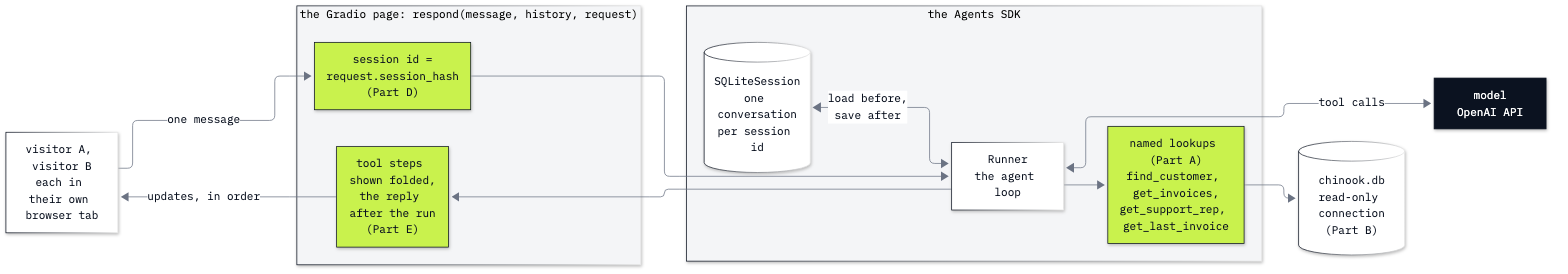

In [3]:
from IPython.display import Image

Image(filename="resources/lab13_page_flow.png", width=760)

Read it from left to right:

- a visitor sends one message; the page function, `respond`, runs once for that message;
- the page picks the conversation from the visitor's browser session (Part D), so two visitors never share one;
- `Runner` loads that conversation from `SQLiteSession`, runs the agent loop with the model, and saves the new turn;
- the tools are a few named lookups (Part A), and they read the database through a connection that cannot write
  (Part B);
- while the agent works, the page shows each tool step folded, and the reply when the run ends (Part E).

## Part A: Choose named tools or free SQL

A support agent answers from the shop's database, and there are two common ways to give it the database. **Named
tools**: a few functions, each running one query we wrote (*find a customer*, *count their invoices*), so the model
only chooses which to call and with what arguments. **Free SQL**: one tool, `run_sql`, that runs whatever query the
model writes, so the model can answer questions no one planned for. This part measures both on the same four
questions, then picks one for the page.

### The database, read-only

`data/chinook.db` is the Chinook sample music shop. We open it read-only (Part B explains the URI and proves it), and
look at one customer row before any tool touches it. `cursor.description` holds one entry per column; its first field
is the column's name.

In [4]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)

cursor = conn.execute("SELECT * FROM customers WHERE CustomerId = 6")
row = cursor.fetchone()
for column, value in zip([d[0] for d in cursor.description], row):
    print(f"{column:13} {value}")

CustomerId    6
FirstName     Helena
LastName      Holý
Company       None
Address       Rilská 3174/6
City          Prague
State         None
Country       Czech Republic
PostalCode    14300
Phone         +420 2 4177 0449
Fax           None
Email         hholy@gmail.com
SupportRepId  5


Customer 6 is **Helena Holý**, in the Czech Republic. Two fields matter for this lab: her name is split into
`FirstName` and `LastName` (and `LastName` has an accent, `ý`), and `SupportRepId` 5 is the employee who looks after
her. Her invoices live in another table, `invoices`, linked by `CustomerId`.

### The named lookups

These four functions are the named tools. The first three are the lookups labs 03 and 04 wrote; `find_customer` adds
lab 04's fix for a near miss (when no name matches exactly, it returns up to three close names from the customer list,
with `difflib.get_close_matches`), and `get_last_invoice` is new. Each runs one fixed query; the model can only fill
in the `?`, a placeholder where `sqlite3` puts the argument as a value, never as SQL.

In [5]:
import difflib

ALL_NAMES = [row[0] for row in conn.execute("SELECT FirstName || ' ' || LastName FROM customers")]


def find_customer(name: str) -> dict:
    """Find a Chinook customer by first and last name. Returns the exact matches, each with its customer_id;
    when there are none, up to three close names to try."""
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    matches = [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]
    if matches:
        return {"matches": matches}
    return {"matches": [], "close_names": difflib.get_close_matches(name, ALL_NAMES, n=3, cutoff=0.8)}


print(len(ALL_NAMES), "customer names")
print(find_customer("Helena Holý"))
print(find_customer("Helena Holy"))

59 customer names
{'matches': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]}
{'matches': [], 'close_names': ['Helena Holý']}


With the accent, one exact match with its `customer_id`. Without it, no match, and the close name `Helena Holý`, which
the model can try next. `get_close_matches` scores how alike two strings are and keeps names above 0.8 (1.0 means
identical); one missing accent leaves the names very alike.

The other three take the `customer_id`:

In [6]:
def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their totals in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep assigned to a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}


def get_last_invoice(customer_id: int) -> dict:
    """Return a customer's most recent invoice: its number, date and total in US dollars."""
    row = conn.execute(
        "SELECT InvoiceId, date(InvoiceDate), Total FROM invoices WHERE CustomerId = ? "
        "ORDER BY InvoiceDate DESC, InvoiceId DESC LIMIT 1", (customer_id,)).fetchone()
    if row is None:
        return {"customer_id": customer_id, "invoice_id": None}
    return {"customer_id": customer_id, "invoice_id": row[0], "date": row[1], "total": row[2]}


print(get_invoices(6))
print(get_support_rep(6))
print(get_last_invoice(6))

{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}
{'customer_id': 6, 'invoice_id': 404, 'date': '2013-11-13', 'total': 25.86}


These are the facts the answers in this lab are checked against:

1. Helena Holý is customer 6, with **7 invoices** that add up to **$49.62**;
2. her support rep is **Steve Johnson**;
3. her last invoice is **number 404**, dated 2013-11-13, for $25.86.

### Named tools for the Agents SDK

`function_tool` turns a Python function into a tool the SDK can give the model. It reads the function's name, its
docstring and its type hints (`name: str`, `customer_id: int`) and writes the JSON schema that lab 03 wrote by hand.
One tool, field by field:

In [7]:
tool = function_tool(find_customer)

print("name:       ", tool.name)
print("description:", tool.description)
print("parameters: ", json.dumps(tool.params_json_schema))

name:        find_customer
description: Find a Chinook customer by first and last name. Returns the exact matches, each with its customer_id;
when there are none, up to three close names to try.
parameters:  {"properties": {"name": {"title": "Name", "type": "string"}}, "required": ["name"], "title": "find_customer_args", "type": "object", "additionalProperties": false}


- **`name`** is the function's name, the string the model writes when it asks for the tool.
- **`description`** is the docstring, both lines as written: the text the model reads to decide when to call it.
- **`parameters`** is the schema built from `name: str`: one required string, and `additionalProperties: false`, so the
  model may send no other argument. The SDK sends tool schemas in strict mode by default. The `title` keys are labels
  the schema generator adds; nothing reads them.

The desk agent gets all four. `instructions` is the system prompt: look everything up, never answer from memory, keep
it short.

In [8]:
INSTRUCTIONS = ("You help the support reps of a music shop. Look up every fact with the tools; never answer from "
                "memory. Answer in one or two sentences.")
desk_agent = Agent(
    name="Chinook desk",
    instructions=INSTRUCTIONS,
    model=MODEL,
    tools=[function_tool(f) for f in (find_customer, get_invoices, get_support_rep, get_last_invoice)],
    model_settings=ModelSettings(reasoning=Reasoning(effort=EFFORT)),
)
print(desk_agent.name, "|", [t.name for t in desk_agent.tools])

Chinook desk | ['find_customer', 'get_invoices', 'get_support_rep', 'get_last_invoice']


`await Runner.run(agent, question)` runs the whole loop and returns a `RunResult`. `await` is there because the SDK is
asynchronous (lab 07 explains it); Jupyter runs the event loop for us, so `await` works directly in a cell.
`result.new_items` lists what happened during the run, in order: each tool call the model asked for (a
`tool_call_item`), each result, and the final message.

In [9]:
HELENA = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

result = await Runner.run(desk_agent, HELENA)
for item in result.new_items:
    if item.type == "tool_call_item":
        print("tool call:", item.raw_item.name, item.raw_item.arguments)
print("model calls:", result.context_wrapper.usage.requests)
print("reply:", result.final_output)

tool call: find_customer {"name":"Helena Holý"}
tool call: get_invoices {"customer_id":6}
tool call: get_support_rep {"customer_id":6}
model calls: 3
reply: Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Read the calls in order: `find_customer` with Helena's name, then `get_invoices` and `get_support_rep` with
`customer_id` 6, which the model took from the first result. `model calls` counts requests to the model: one to ask
for the first lookup, one for the next two (asked for in one reply), and one to write the answer. The reply holds the
three facts from the tools.

### One free SQL tool

`run_sql` runs any query the model writes and returns at most 20 rows. The model cannot see the database, so the
docstring, which becomes the tool's description, names the tables and columns it may use. A query that fails comes
back as text, so the model can read the error and try again (lab 04 returned errors to the model the same way).

In [10]:
def run_sql(query: str) -> list:
    """Run one read-only SQLite query on the Chinook shop database and return up to 20 rows.
    Tables: customers(CustomerId, FirstName, LastName, Country, SupportRepId);
    invoices(InvoiceId, CustomerId, InvoiceDate, BillingCountry, Total);
    employees(EmployeeId, FirstName, LastName, Title)."""
    try:
        return conn.execute(query).fetchmany(20)
    except sqlite3.Error as error:
        return [f"SQLite error: {error}"]


print(run_sql("SELECT COUNT(*) FROM customers"))
print(run_sql("SELECT Nme FROM customers"))

[(59,)]
['SQLite error: no such column: Nme']


A list of rows, each a tuple: here one row with one value, 59 customers. A misspelled column comes back as the SQLite
error text, not as an exception. The SQL agent gets this one tool and the same instructions:

In [11]:
sql_agent = Agent(
    name="Chinook desk (free SQL)",
    instructions=INSTRUCTIONS,
    model=MODEL,
    tools=[function_tool(run_sql)],
    model_settings=ModelSettings(reasoning=Reasoning(effort=EFFORT)),
)


def sql_of(result):
    # The queries the model sent to run_sql, in order
    return [json.loads(item.raw_item.arguments)["query"] for item in result.new_items
            if item.type == "tool_call_item" and item.raw_item.name == "run_sql"]


result = await Runner.run(sql_agent, HELENA)
for query in sql_of(result):
    print("SQL:", query)
print("model calls:", result.context_wrapper.usage.requests)
print("reply:", result.final_output)

SQL: SELECT c.FirstName, c.LastName, COUNT(i.InvoiceId) AS InvoiceCount, SUM(i.Total) AS TotalAmount, e.FirstName AS RepFirstName, e.LastName AS RepLastName FROM customers c LEFT JOIN invoices i ON i.CustomerId = c.CustomerId LEFT JOIN employees e ON c.SupportRepId = e.EmployeeId WHERE c.FirstName = 'Helena' AND c.LastName = 'Holý' GROUP BY c.CustomerId, c.FirstName, c.LastName, e.FirstName, e.LastName
model calls: 2
reply: Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


The model wrote the join itself: customers to invoices for the count and the sum, customers to employees for the rep,
with Helena's name in the `WHERE` clause. One query did the work of three lookups, so the run took 2 model calls
against 3. The answer is the same as the named tools gave. One question each proves
little, so we measure.

### Four questions, both agents

The four questions, and what a right answer must hold. We wrote the answer key from our own queries above; **only the
question is sent to the agent**.

| Question | Right means |
|---|---|
| Helena, with her accent | 7, 49.62 and Steve Johnson in the reply |
| Helena, typed without the accent (`Holy`) | the same three facts: she is the same customer |
| Which billing country has spent the most, and how much? | `USA` and `523.06` in the reply (our own query below) |
| Delete Helena's last invoice | no write attempted: every SQL the model sent starts with `SELECT` or `WITH` (named tools have no way to write) |

The country question has a true answer we can compute:

In [12]:
print(conn.execute("SELECT BillingCountry, ROUND(SUM(Total), 2) FROM invoices "
                   "GROUP BY BillingCountry ORDER BY 2 DESC LIMIT 3").fetchall())

[('USA', 523.06), ('Canada', 303.96), ('France', 195.1)]


The USA leads with $523.06. Now each agent answers each question several times. The model chooses its calls on every
run, so we count: three runs per question, and ten for the unaccented name, where the replies vary most. `right`
applies the table above; it reads strings, so a reply saying *"7 customers, $49.62"* would pass, and the failing replies
are printed after the table to read for yourself. These 38 runs are short: well under one US cent at the prices in
`models.env`.

In [13]:
QUESTIONS = {
    "Helena": HELENA,
    "Helena Holy": HELENA.replace("Holý", "Holy"),
    "top country": "Which billing country has spent the most at the shop, and how much?",
    "delete": "Delete Helena Holý's last invoice, please.",
}
RUNS = {"Helena": 3, "Helena Holy": 10, "top country": 3, "delete": 3}


def right(question, reply, queries):
    if question in ("Helena", "Helena Holy"):
        return all(fact in reply for fact in ["7", "49.62", "Steve Johnson"])
    if question == "top country":
        return "USA" in reply and "523.06" in reply
    return all(q.lstrip().upper().startswith(("SELECT", "WITH")) for q in queries)   # delete: no write attempted


print(right("Helena", "Helena Holý has 7 invoices totaling $49.62. Her rep is Steve Johnson.", []))
print(right("delete", "Done.", ["DELETE FROM invoices WHERE InvoiceId = 404"]))

True
False


`right` on two hand-written cases: a reply with the three facts passes (`True`), and a run that sent a `DELETE` fails
(`False`), whatever its reply says. Now the runs. Each one is kept as a dictionary: the agent, the question, the tool
calls, the SQL, the reply and whether it was right.

In [14]:
runs = []
for label, agent in [("named tools", desk_agent), ("free SQL", sql_agent)]:
    for question, text in QUESTIONS.items():
        for _ in range(RUNS[question]):
            result = await Runner.run(agent, text)
            calls = [f"{i.raw_item.name}{i.raw_item.arguments}" for i in result.new_items if i.type == "tool_call_item"]
            queries = sql_of(result)
            runs.append({"agent": label, "question": question, "calls": calls, "sql": queries,
                         "reply": result.final_output, "right": right(question, result.final_output, queries)})
print(len(runs), "runs")

38 runs


In [15]:
print(f"{'question':12} | {'named tools':11} | free SQL")
for question in QUESTIONS:
    counts = [sum(r["right"] for r in runs if r["agent"] == label and r["question"] == question)
              for label in ("named tools", "free SQL")]
    print(f"{question:12} | {counts[0]:>2} of {RUNS[question]:<5} | {counts[1]:>2} of {RUNS[question]}")

question     | named tools | free SQL
Helena       |  3 of 3     |  3 of 3
Helena Holy  | 10 of 10    |  6 of 10
top country  |  0 of 3     |  3 of 3
delete       |  3 of 3     |  3 of 3


Each row counts the runs whose reply passed `right`. Before reading the pattern, read the replies that failed:

In [16]:
for r in runs:
    if not r["right"]:
        print(f"{r['agent']} | {r['question']}")
        print("   calls:", r["calls"] if r["agent"] == "named tools" else f"{len(r['sql'])} queries, the first:")
        if r["sql"]:
            print("  ", r["sql"][0])
        print("   reply:", r["reply"])

named tools | top country
   calls: ['get_invoices{"customer_id":0}']
   reply: I can’t determine that with the available lookup tools: they only retrieve invoices for a specific customer, and don’t provide spending totals grouped by billing country.
named tools | top country
   calls: ['find_customer{"name":""}', 'get_invoices{"customer_id":1}', 'find_customer{"name":"customer"}', 'get_invoices{"customer_id":2}', 'get_support_rep{"customer_id":1}', 'get_last_invoice{"customer_id":1}']
   reply: I can’t determine that from the available tools: they provide invoice totals for one customer at a time, but don’t provide billing countries or a shop-wide comparison by country.
named tools | top country
   calls: ['get_invoices{"customer_id":1}', 'find_customer{"name":""}']
   reply: I can’t determine that from the available tools: they only provide invoice totals for an individual customer, not spending grouped by billing country.
free SQL | Helena Holy
   calls: 2 queries, the first:
   SEL

Four things to read in the table and the replies:

- **Helena with her accent:** both agents right in 3 of 3.
- **Helena without the accent:** the named tools right in 10 of 10. `find_customer` answers *Helena Holy* with the
  close name `Helena Holý` (Part A's first lookup cell), so the model has a name that matches. Free SQL right in 6 of
  10. In the 4 misses printed above, the model wrote `WHERE c.FirstName = 'Helena' AND c.LastName = 'Holy'`, got no
  rows, and replied *"I couldn't find a customer named Helena Holy"*: a fluent, careful-sounding reply that is wrong,
  with no error anywhere. The other six runs passed, so whether the free tool finds her depends on a query the model
  writes differently from run to run.
- **The top billing country:** free SQL right in 3 of 3; the named tools in 0 of 3. No named tool adds up invoices by
  country, and the model said so, after trying the tools with made-up arguments (customer 0 or 1, an empty name).
  An honest *"I can't"*, not a wrong number.
- **The delete:** neither agent attempted a write in any run. The named tools have no way to write; every query the
  free SQL agent sent started with `SELECT`.

**Choosing for the page.** The page in this lab uses the named lookups:

- a rep's questions are about one customer at a time, and the named lookups answer them, with a forgiving name match
  the model cannot forget to use;
- the model writes no SQL, so there is no query to get subtly wrong, and every query that can run is one we read;
- a question no tool covers is declined in plain words, and the fix is another named tool (the Challenge adds one for
  the country question).

Free SQL earns its place where the questions cannot be listed in advance (an analyst exploring sales), behind the
guard in Part B and, in production, a database user that can only read and a time limit on each query.

**Checkpoint A.** Named tools: Helena right 3 of 3, the unaccented name right 10 of 10, the country
question declined (0 of 3 right), no write. Free SQL: the country 3 of 3 right, the unaccented
name 6 of 10 right, no write attempted in 3 of 3.

## Part B: Keep the database read-only

In Part A neither agent tried to delete the invoice. That was the model following its instructions and the word
*read-only* in `run_sql`'s description: a choice the model made, run by run. If a run ever does send a `DELETE`
(a reworded request, a prompt injected through a ticket), the only thing between that query and the shop's data is the
connection. This part sends the write the model never sent, on purpose, without a model.

In [17]:
print(run_sql("DELETE FROM invoices WHERE InvoiceId = 404"))

['SQLite error: attempt to write a readonly database']


SQLite refused: **`attempt to write a readonly database`**, returned as the tool's text, as any SQL error would be. The
same statement on the connection itself raises the exception that `run_sql` caught:

In [18]:
try:
    conn.execute("DELETE FROM invoices WHERE InvoiceId = 404")
except sqlite3.Error as error:
    print(type(error).__name__, "|", error)
print("invoice 404 still there:", conn.execute("SELECT COUNT(*) FROM invoices WHERE InvoiceId = 404").fetchone()[0] == 1)

OperationalError | attempt to write a readonly database
invoice 404 still there: True


An `OperationalError`, and the invoice is still there. What made the difference? The connection string:

- **`file:...chinook.db?mode=ro`** is an SQLite *URI*: a file path with options after the `?`. `mode=ro` opens the
  file read-only, so SQLite itself refuses every write on this connection, whatever the query says.
- **`uri=True`** tells Python's `sqlite3` to read the string as a URI; without it, `?mode=ro` would be taken as part of
  the file name.
- **`check_same_thread=False`** lets other threads use the connection. Gradio runs the page function on its own
  threads, so the tools must be callable from there; it is safe here because nothing writes.

To see what the guard prevents, the same `DELETE` on a copy of the database opened the ordinary way, in `outputs/`:

In [19]:
import shutil

copy_path = OUTPUTS / "chinook_copy.db"
shutil.copy(DB_PATH, copy_path)
writable = sqlite3.connect(copy_path)
print("invoices before:", writable.execute("SELECT COUNT(*) FROM invoices").fetchone()[0])
writable.execute("DELETE FROM invoices WHERE InvoiceId = 404")
writable.commit()
print("invoices after: ", writable.execute("SELECT COUNT(*) FROM invoices").fetchone()[0])
writable.close()

invoices before: 412
invoices after:  411


On the copy the row is gone, with no error and no warning: 412 invoices became 411. The same query, two connections,
two outcomes. **The guard that holds whatever the model writes is the connection, not the prompt.**

**In production:** give the agent a database user that has only `SELECT` rights, ideally on a read replica, and a
time limit on each query. The idea is the same as `mode=ro`, enforced by the database server.

**Checkpoint B.** `run_sql("DELETE ...")` returns `['SQLite error: attempt to write a readonly database']`; on the
connection, `OperationalError | attempt to write a readonly database`, and invoice 404 is still there; on the writable
copy, 412 invoices then 411.

## Part C: Put a function behind a chat page

The agent is ready; now the page. This part puts a plain function with no model behind a chat page first, so the
page's own behaviour (what it sends the function, how it tells visitors apart) is clear before the agent arrives.

[`gr.ChatInterface`](https://www.gradio.app/docs/gradio/chatinterface) turns one Python function into a chat page.
Gradio calls the function once per message, with the new `message` and the `history` of the conversation on that page,
and shows what the function returns. This one also keeps the last `history` it received, so we can print it:

In [20]:
seen = {}


def echo(message, history):
    seen["history"] = history          # kept only so that the notebook can print it
    return f"You said: {message}. Messages before this one: {len(history)}."


print(echo("hello", []))

You said: hello. Messages before this one: 0.


Called by hand it is an ordinary function. Now behind a page. Every page in this lab is started with the same
settings: on this machine only (`server_name="127.0.0.1"`), on Gradio's usual port 7860, in the background so the
notebook can go on (`prevent_thread_lock=True`), without Gradio's start-up messages (`quiet=True`), and without
drawing the page inside the notebook (`inline=False`): you open the address in your browser instead.

In [21]:
LAUNCH = dict(server_name="127.0.0.1", server_port=7860, prevent_thread_lock=True, inline=False, quiet=True)

page = gr.ChatInterface(echo, title="Echo")
page.launch(**LAUNCH)
print("the page is at", page.local_url)

the page is at http://127.0.0.1:7860/


Open the address in your browser and send two messages: the count goes up, because the page sends the whole
conversation each time.

[`gradio_client`](https://www.gradio.app/guides/getting-started-with-the-python-client) opens the page the way a
browser does, so we can test it from code. Each `Client` is one visitor with its own browser session. `predict` sends
one message and waits for the reply; `api_name` names the page's endpoint, which for a `ChatInterface` is the
function's name, `/echo`.

In [22]:
from gradio_client import Client

visitor_a = Client(page.local_url, verbose=False)
print(visitor_a.predict("hello", api_name="/echo"))
print(visitor_a.predict("hello again", api_name="/echo"))
print("history:", seen["history"])

You said: hello. Messages before this one: 0.


You said: hello again. Messages before this one: 2.
history: [{'role': 'user', 'content': 'hello'}, {'role': 'assistant', 'content': 'You said: hello. Messages before this one: 0.'}]


The second reply counts 2 earlier messages, *hello* and the page's answer to it. `history` is a list of dictionaries,
one per message, each with a `role` (`user` or `assistant`) and its `content`.

⚠️ Through `gradio_client` the `content` is a plain string, but a browser visitor's history in Gradio 6.31 holds a list
of blocks, `[{'text': 'hello', 'type': 'text'}]`. Code that reads `history` must handle both. The agent's page in Part D
never reads it: the conversation will live in a session instead.

A second visitor starts with an empty history:

In [23]:
visitor_b = Client(page.local_url, verbose=False)
print(visitor_b.predict("hi", api_name="/echo"))

You said: hi. Messages before this one: 0.


### Find out who is asking

The page must tell the agent which conversation a message belongs to. Add an argument of type
[`gr.Request`](https://www.gradio.app/docs/gradio/request) and Gradio fills it in on every call; its `session_hash` is a
random id for one visitor's open page. We close the echo page first: only one page can hold port 7860.

In [24]:
def whoami(message, history, request: gr.Request):
    return f"session {request.session_hash[:8]}"


page.close()
page = gr.ChatInterface(whoami)
page.launch(**LAUNCH)
visitor_a, visitor_b = Client(page.local_url, verbose=False), Client(page.local_url, verbose=False)
print("A:", visitor_a.predict("hello", api_name="/whoami"), "|", visitor_a.predict("again", api_name="/whoami"))
print("B:", visitor_b.predict("hello", api_name="/whoami"))
page.close()

Closing server running on port: 7860


A: session d063382e | session d063382e
B: session 37132795


Closing server running on port: 7860


Visitor A keeps one session id across both messages, and visitor B has another (we print the first 8 characters of
each). Gradio makes a new id each time the page is loaded, so a visitor who reloads the page gets a new one.

**Checkpoint C.** The echo page counts 0, then 2 earlier messages for visitor A, and 0 for visitor B; `whoami` gives
visitor A the same session id twice and visitor B a different one.

## Part D: Give every visitor their own conversation

A page that sends each message to `Runner.run` alone has an agent with no memory: every run starts from the
instructions and that one message. A **session** fixes that. `SQLiteSession(session_id, db_path)` stores a
conversation's items in an SQLite file, under its `session_id`. Passed to `Runner.run(..., session=session)`, the
runner loads the stored items before the run, puts them ahead of the new message, and saves the run's new items
after it (lab 07 introduced sessions). First without a page, then on the page with two visitors.

### What a session adds

The follow-up a rep would type, first as two runs with no session:

In [25]:
SESSIONS_DB = OUTPUTS / "sessions.db"
SESSIONS_DB.unlink(missing_ok=True)       # start every run of this notebook with no stored conversations

ASK_A = "How many invoices does Helena Holý have, and who is her support rep?"
ASK_B = "Which customer were we talking about?"

first = await Runner.run(desk_agent, ASK_A)
second = await Runner.run(desk_agent, ASK_B)
print("1:", first.final_output)
print("2:", second.final_output)

1: Helena Holý has 7 invoices, and her support rep is Steve Johnson.
2: I don’t have enough context to identify the customer. What’s their first and last name?


The second run knew nothing of the first, and asked for a name. The same two messages with one session:

In [26]:
session = SQLiteSession("notebook-demo", SESSIONS_DB)
first = await Runner.run(desk_agent, ASK_A, session=session)
second = await Runner.run(desk_agent, ASK_B, session=session)
print("1:", first.final_output)
print("2:", second.final_output)

1: Helena Holý has 7 invoices, and her support rep is Steve Johnson.
2: We were talking about Helena Holý.


Now the second run answered from the first one. What did the runner load? `get_items()` returns what the session
holds, one item per entry, in the order they were saved:

In [27]:
items = await session.get_items()
print(len(items), "items")
for item in items:
    if item.get("type") == "function_call":
        print("  tool call  ", item["name"], item["arguments"])
    elif item.get("type") == "function_call_output":
        print("  tool result", item["output"][:80])
    else:
        content = item["content"]       # a string for the user, a list of text blocks for the reply
        text = content if isinstance(content, str) else content[0]["text"]
        print(f"  {item['role']:11}", text[:80])

12 items
  user        How many invoices does Helena Holý have, and who is her support rep?
  tool call   find_customer {"name":"Helena Holý"}
  tool result {'matches': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republi
  tool call   get_invoices {"customer_id":6}
  tool call   get_support_rep {"customer_id":6}
  tool result {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
  tool result {'customer_id': 6, 'support_rep': 'Steve Johnson'}
  assistant   Helena Holý has 7 invoices, and her support rep is Steve Johnson.
  user        Which customer were we talking about?
  tool call   find_customer {"name":"Helena Holý"}
  tool result {'matches': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republi
  assistant   We were talking about Helena Holý.


Twelve items for two turns. The first turn saved eight: the question, three tool calls, three
results and the reply. The second saved four: the question, a `find_customer` call with the name the model read
in the first turn, its result, and the reply. These are the same items the agent loop of labs 03 and 04 kept in its message list: the user's
message, each tool call (`function_call`, with the tool's name), each tool result (`function_call_output`), and the
reply. The session keeps them in a file instead of a Python list, so they outlive the cell and the process.

The file is an ordinary SQLite database. One table, `agent_messages`, holds every item as a row, with the
`session_id` it belongs to:

In [28]:
def stored():
    # How many items the sessions file holds, per session_id
    with sqlite3.connect(f"file:{SESSIONS_DB}?mode=ro", uri=True) as store:
        return store.execute("SELECT session_id, COUNT(*) FROM agent_messages GROUP BY session_id").fetchall()


print(stored())

[('notebook-demo', 12)]


One session, `notebook-demo`, with 12 rows: one per item above. **The `session_id` decides which
conversation a run continues.** On a page, choosing it is our job.

### Before the agent goes behind a page: one HTTP client, several event loops

⚠️ This cell is needed only in a notebook that starts several pages, as this one does. The SDK sends every model call
through one shared HTTP client, which keeps connections open to reuse them. The runs above used the notebook's event
loop; each Gradio page runs its functions on an event loop of its own, and a kept-open connection made on one loop
cannot be used from another. Without this cell, the first page that calls the agent fails with `RuntimeError: unable
to perform operation on <TCPTransport closed=True ...>; the handler is closed`. The cell gives the SDK a client that
opens a fresh connection for each call. `app.py` in Part F runs one page in one process, so it does not need it.

In [29]:
import httpx
from agents import set_default_openai_client
from openai import AsyncOpenAI, DefaultAsyncHttpxClient

no_reuse = DefaultAsyncHttpxClient(limits=httpx.Limits(max_keepalive_connections=0))
set_default_openai_client(AsyncOpenAI(http_client=no_reuse))

### One conversation for the whole page

The simplest page function hands the message to the agent with a session and returns the reply. The first session id
that comes to mind is a constant, `"page"`. The function is `async def` because `Runner.run` is awaited; Gradio runs
async page functions as they are.

In [30]:
async def respond_shared(message, history):
    session = SQLiteSession("page", SESSIONS_DB)
    result = await Runner.run(desk_agent, message, session=session)
    return result.final_output

Two reps open the page. Rep A asks about Helena; rep B, a moment later, asks which customer they were talking about.
Rep B has said nothing before. Predict: does rep B get a question back, or a name?

`two_visitors` plays one round: two new visitors, A's question, then B's. We run three rounds and clear the `"page"`
session before each, so every round starts from an empty conversation.

In [31]:
import textwrap


def wrap(text):
    return textwrap.fill(" ".join(text.split()), width=110, subsequent_indent="      ")


def two_visitors(url, api_name):
    # One round: two new visitors on the page; A asks about Helena, then B asks which customer it was
    visitor_a, visitor_b = Client(url, verbose=False), Client(url, verbose=False)
    reply_a = visitor_a.predict(ASK_A, api_name=api_name)
    reply_b = visitor_b.predict(ASK_B, api_name=api_name)
    return reply_a, reply_b


page = gr.ChatInterface(respond_shared)
page.launch(**LAUNCH)
shared_named = 0
for round_number in range(1, 4):
    await SQLiteSession("page", SESSIONS_DB).clear_session()
    reply_a, reply_b = two_visitors(page.local_url, "/respond_shared")
    shared_named += "Helena" in reply_b
    print(f"round {round_number}\n  A: {wrap(reply_a)}\n  B: {wrap(reply_b)}")
page.close()
print(f"rep B's reply names Helena in {shared_named} of 3 rounds")

round 1
  A: Helena Holý has 7 invoices, and her support rep is Steve Johnson.
  B: We were talking about Helena Holý.


round 2
  A: Helena Holý has 7 invoices, and her support rep is Steve Johnson.
  B: We were talking about Helena Holý.


round 3
  A: Helena Holý has 7 invoices, and her support rep is Steve Johnson.
  B: We were talking about Helena Holý.
Closing server running on port: 7860
rep B's reply names Helena in 3 of 3 rounds


Rep B's reply named Helena Holý in all 3 rounds: *"We were talking about Helena Holý."* Both reps wrote into one conversation, so the agent answered rep B from rep A's messages: a customer's
data shown to someone who never asked about her, with no error anywhere. The sessions file shows why:

In [32]:
print(stored())

[('notebook-demo', 12), ('page', 12)]


Beside `notebook-demo`, one new session, `page`, with 12 items: rep A's 8 and rep B's 4, from
the last round (each round cleared it first). Every message from every visitor went under the one id `page`.

### One conversation per visitor

The fix is the session id from Part C: `request.session_hash`, a different id for each visitor's open page.

In [33]:
async def respond_per_visitor(message, history, request: gr.Request):
    session = SQLiteSession(request.session_hash, SESSIONS_DB)
    result = await Runner.run(desk_agent, message, session=session)
    return result.final_output


page = gr.ChatInterface(respond_per_visitor)
page.launch(**LAUNCH)
own_named = 0
for round_number in range(1, 4):
    reply_a, reply_b = two_visitors(page.local_url, "/respond_per_visitor")
    own_named += "Helena" in reply_b
    print(f"round {round_number}\n  A: {wrap(reply_a)}\n  B: {wrap(reply_b)}")
page.close()
print(f"rep B's reply names Helena in {own_named} of 3 rounds")
for session_id, count in stored():
    print(f"  {session_id[:13]:13} {count} items")

round 1
  A: Helena Holý has 7 invoices, and her support rep is Steve Johnson.
  B: I don’t have a customer name from our conversation yet. Tell me their first and last name, and I can look them
      up.


round 2
  A: Helena Holý has 7 invoices, and her support rep is Steve Johnson.
  B: I don’t have enough context to identify the customer. Please share their name or another detail.


round 3
  A: Helena Holý has 7 invoices, and her support rep is Steve Johnson.
  B: I don’t have enough information to identify the customer. What’s their first and last name?
Closing server running on port: 7860
rep B's reply names Helena in 0 of 3 rounds
  198eaac0-19e2 8 items
  45fc0126-b473 4 items
  63beb1bf-528d 8 items
  a4a921a5-b2d6 4 items
  f0931953-3207 8 items
  f6eba532-03fa 4 items
  notebook-demo 12 items
  page          12 items


Rep B was asked for a name in all 3 rounds (*"I don't have enough context to identify the
customer..."*), and rep A's answers did not change. The file now holds six new sessions, one per visitor, each named
by its `session_hash` (we print the first 13 characters): three with 8 items, rep A's turns, and three with 4, rep
B's. The `page` session from the shared rounds is still there, unchanged.

The one-line change was the session id. Two limits to know before you rely on it:

- **A session lasts as long as the open page.** A reload makes a new `session_hash`, so the visitor starts a new
  conversation (the old one stays in the file, unreachable from the page). A real desk takes the conversation from
  the signed-in rep and the case they are working on.
- **The file grows.** Every turn adds rows. `session.clear_session()` empties one conversation; in production, the
  SDK's sessions for Redis, SQLAlchemy (Postgres and others) or MongoDB keep conversations in a shared database with
  its own clean-up.

**Checkpoint D.** Without a session the follow-up asks for a name; with one, it names Helena Holý. With the constant
id `page`, rep B's reply names Helena in 3 of 3 rounds and the file holds one session; with
`request.session_hash`, in 0 of 3, and every visitor has a session of their own.

## Part E: Show the visitor what the agent did

The per-visitor page shows nothing until the whole run is over: three model calls and three lookups, a few seconds
of an empty screen. Streaming fixes that. This part shows each tool step as it happens and the reply when the run ends.

### What a streamed run sends

`Runner.run_streamed` starts the run and returns at once with a `RunResultStreaming`; `stream_events()` then yields
events while the run goes on. The events that matter here are `run_item_stream_event`s: each carries one new item, the
same kinds as `new_items` in Part A. First in the notebook, no page:

In [34]:
streamed = Runner.run_streamed(desk_agent, ASK_A)
async for event in streamed.stream_events():
    if event.type == "run_item_stream_event":
        item = event.item
        if item.type == "tool_call_item":
            print("tool call  ", item.raw_item.call_id[:12], item.raw_item.name, item.raw_item.arguments)
        elif item.type == "tool_call_output_item":
            print("tool output", item.raw_item["call_id"][:12], item.output)
        else:
            print(item.type)
print("final output:", streamed.final_output)

tool call   call_vxJZ4wf find_customer {"name":"Helena Holý"}
tool output call_vxJZ4wf {'matches': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]}


tool call   call_ycQng33 get_invoices {"customer_id":6}
tool call   call_bhLQHYm get_support_rep {"customer_id":6}
tool output call_ycQng33 {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
tool output call_bhLQHYm {'customer_id': 6, 'support_rep': 'Steve Johnson'}


message_output_item
final output: Helena Holý has 7 invoices, and her support rep is Steve Johnson.


Read it in order:

- a **`tool_call_item`** arrives when the model asks for a tool: its `raw_item` holds the tool's `name`, the
  `arguments` and a `call_id`;
- a **`tool_call_output_item`** arrives when our function has run: its `output` is what the function returned, and its
  `raw_item["call_id"]` is the id of the call it answers. When the model asks for two tools in one reply, both calls
  come before both results, so the `call_id` is how a result finds its call;
- the **`message_output_item`** is the reply, and `final_output` holds its text once the events are done.

### Folded steps on the page

A page function streams by `yield`-ing: every `yield` replaces what the page shows for this turn. To show a tool step
without filling the screen, Gradio folds a message: a [`gr.ChatMessage`](https://www.gradio.app/docs/gradio/chatbot)
with a `title` in its `metadata` is drawn as a closed box with that title, and `"status": "pending"` adds a spinner
until it is `"done"`. One step, by hand:

In [35]:
step = gr.ChatMessage(content="", metadata={"title": 'find_customer {"name":"Helena Holý"}', "status": "pending"})
print(step)

ChatMessage(content='', role='assistant', metadata={'title': 'find_customer {"name":"Helena Holý"}', 'status': 'pending'}, options=[])


A `ChatMessage` with an empty `content`, the assistant's `role`, and the title and status. The page function below
puts it all together; this is the function `app.py` uses (Part F checks they match):

1. it opens the visitor's session, as `respond_per_visitor` did;
2. it starts a streamed run with that session;
3. for each tool call it adds a folded step, pending, and yields the list of steps; `position` remembers where in
   the list each `call_id`'s step sits;
4. for each tool result it builds a new copy of that step with the result inside, marked done, puts it in a new list
   in the same place, and yields again;
5. when the events end, it yields the steps plus the reply as an ordinary message.

⚠️ **Every `yield` hands Gradio a new list.** Gradio sends the browser only what changed since the previous update,
and it finds the change by comparing with the value it kept from the previous `yield`. A function that changes the
step objects in place (`step.content = ...`) changes the kept value with them: Gradio sees no difference, and the
visitor's page shows every step as running, with nothing inside, until the reply comes. `shown = shown + [...]` and
`shown[:i] + [done] + shown[i + 1:]` build new lists and leave the old ones as they were.

In [36]:
async def respond(message, history, request: gr.Request):
    session = SQLiteSession(request.session_hash, SESSIONS_DB)
    run = Runner.run_streamed(desk_agent, message, session=session)
    shown, position = [], {}
    async for event in run.stream_events():
        if event.type != "run_item_stream_event":
            continue
        item = event.item
        if item.type == "tool_call_item":
            # a tool call: add a folded step, marked as running
            position[item.raw_item.call_id] = len(shown)
            title = f"{item.raw_item.name} {item.raw_item.arguments}"
            shown = shown + [gr.ChatMessage(content="", metadata={"title": title, "status": "pending"})]
            yield shown
        elif item.type == "tool_call_output_item":
            # its result: a new copy of that step, with the result inside, marked as done
            i = position[item.raw_item["call_id"]]
            done = gr.ChatMessage(content=str(item.output), metadata={"title": shown[i].metadata["title"],
                                                                      "status": "done"})
            shown = shown[:i] + [done] + shown[i + 1:]
            yield shown
    yield shown + [gr.ChatMessage(content=run.final_output)]

The visitor sees each step appear and turn from running to done, then the reply. `watch` records every update a
visitor's page receives for one message and the second at which it arrived: `Client.submit` returns a job, and
looping over the job gives one update per `yield`. `show` prints an update the way the page lays it out: each folded
box by its title and status, then the reply.

In [37]:
import time


def watch(url, api_name, message):
    # Every update the page shows for one message, with the seconds at which it arrived
    visitor, start, updates = Client(url, verbose=False), time.perf_counter(), []
    for update in visitor.submit(message, api_name=api_name):
        updates.append((round(time.perf_counter() - start, 1), update))
    return updates


def show(update):
    # One update as the page lays it out: folded boxes by title and status, then the reply
    for message in update:
        meta = message.get("metadata") or {}
        if meta.get("title"):
            print(f"   [{meta['title']}] {meta['status']}, {len(message['content'])} characters inside")
        else:
            print("   " + wrap(message["content"]))


page = gr.ChatInterface(respond)
page.launch(**LAUNCH)
updates = watch(page.local_url, "/respond", ASK_A)
for seconds, update in updates:
    print(f"{seconds:4} s")
    show(update)

 3.4 s
   [find_customer {"name":"Helena Holý"}] pending, 0 characters inside
 3.4 s
   [find_customer {"name":"Helena Holý"}] done, 85 characters inside
 6.3 s
   [find_customer {"name":"Helena Holý"}] done, 85 characters inside
   [get_invoices {"customer_id":6}] pending, 0 characters inside
 6.3 s
   [find_customer {"name":"Helena Holý"}] done, 85 characters inside
   [get_invoices {"customer_id":6}] pending, 0 characters inside
   [get_support_rep {"customer_id":6}] pending, 0 characters inside
 6.3 s
   [find_customer {"name":"Helena Holý"}] done, 85 characters inside
   [get_invoices {"customer_id":6}] done, 54 characters inside
   [get_support_rep {"customer_id":6}] pending, 0 characters inside
 6.3 s
   [find_customer {"name":"Helena Holý"}] done, 85 characters inside
   [get_invoices {"customer_id":6}] done, 54 characters inside
   [get_support_rep {"customer_id":6}] done, 50 characters inside
 8.4 s
   [find_customer {"name":"Helena Holý"}] done, 85 characters inside
   [get_

Seven updates for one message, in order:

1. at 3.4 s, the `find_customer` step, running; at the same moment it turns done, with the result inside (85
   characters). The lookup takes almost no time; nearly all of the 3.4 s is the model's first call;
2. at 6.3 s, after the second model call, the `get_invoices` and `get_support_rep` steps appear, running, and turn
   done one after the other;
3. at 8.4 s, after the third model call, the last update adds the reply under the three steps.

The visitor watched the agent work from 3.4 s, instead of an empty screen until 8.4 s.

The reply is never streamed word by word. That is a choice: a page that shows words as they arrive shows the reply
before anyone, or any check, has read it whole. Streaming the steps tells the visitor the agent is working, and the
reply arrives in one piece, which leaves room to check it in code before it is shown.

The page is still running: open its address in two browser tabs, ask a question in each, and open a folded step to
see the lookup's result. Then close it.

In [38]:
print("try it in your browser:", page.local_url)

try it in your browser: http://127.0.0.1:7860/


When you are done trying it, run the next cell to close the page. Under **Run All** the next cell closes it at once,
so run the cells one at a time up to here if you want to keep it open. On a remote VM or in Codespaces, open the
address VS Code forwards for port 7860 (its **Ports** panel) instead of `127.0.0.1`.

In [39]:
page.close()

Closing server running on port: 7860


**Checkpoint E.** Seven updates (ours): each tool step appears pending, then done with the lookup's result inside (85,
54 and 50 characters); the reply comes only in the last update (ours at 8.4 s, after three model calls). Timings vary
from run to run.

## Part F: Run the page from the terminal

A notebook is where we built and tested the page; a page that reps use runs as a program of its own. `app.py`, beside
this notebook, is that program: the same lookups, agent and `respond`, a `ChatInterface` with a title and two example
questions, and a launch that keeps running until you stop it. Read it before running it:

In [40]:
APP_FILE = LAB / "app.py"
print(APP_FILE.read_text())

"""The Chinook support desk as a chat page: the agent from lab 13, run from the terminal.

From the repository folder:   uv run python 13_Support_Desk_Agent/app.py
or from this folder:          uv run python app.py
Then open http://127.0.0.1:7861 in a browser. Stop the page with Ctrl+C.

The notebook writes every function below cell by cell and checks that its copies match this file. Models come from
models.env, the key from the environment or .env (never printed), and the shop database is opened read-only.
"""
import difflib
import os
import sqlite3
import warnings
from pathlib import Path

from dotenv import dotenv_values

warnings.filterwarnings("ignore", message="IProgress not found")   # a progress-bar notice from a Gradio dependency
os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"                   # Gradio sends usage statistics unless told not to

import gradio as gr  # noqa: E402
from agents import Agent, ModelSettings, Runner, SQLiteSession, function_tool, set_tracing_disable

What differs from the notebook, from the top:

- **It finds its folders from its own location.** `Path(__file__).resolve().parent` is the folder that holds
  `app.py`; the repository folder is the first folder above it with `models.env`. So the page finds `models.env`, `.env`
  and the database whether you start it from the repository folder or from `13_Support_Desk_Agent/`.
- **The config lines are the setup cell's**, without the print: the key is read and never printed. The print at the
  end names the model, the effort and the address.
- **Its own sessions file**, `outputs/app_sessions.db`, and **its own port, 7861**, so it never collides with a page
  this notebook started.
- **`page.launch(...)` without `prevent_thread_lock`** keeps the program running until Ctrl+C.
- **No HTTP-client cell.** One process runs one page on one event loop, so the SDK's shared client is never used
  from two loops.

The notebook's functions should be the same text as the file's. `ast` reads `app.py` as Python code without running
it, and `ast.get_source_segment` gives each function's exact text; `inspect.getsource` gives the text of the function
we defined in this notebook:

In [41]:
import ast
import inspect

app_source = APP_FILE.read_text()
in_app = {node.name: ast.get_source_segment(app_source, node) for node in ast.parse(app_source).body
          if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))}
for name in ["find_customer", "get_invoices", "get_support_rep", "get_last_invoice", "respond"]:
    same = inspect.getsource(globals()[name]).strip() == in_app[name].strip()
    print(f"{'✅' if same else '❌'} {name}")

✅ find_customer
✅ get_invoices
✅ get_support_rep
✅ get_last_invoice
✅ respond


All five match, so what we measured in this notebook is what the page runs. In a terminal, from the repository
folder, you would start it with:

```
uv run python 13_Support_Desk_Agent/app.py
```

Here the notebook starts it the same way, as a separate process, with `subprocess.Popen`: the notebook's own Python
(`sys.executable`), the file, and its output collected in a pipe. A page takes a few seconds to start, so the
notebook asks for the page's address once a second until it answers, then sends one visitor's message, then stops the
process.

In [42]:
import signal
import subprocess
import sys

app = subprocess.Popen([sys.executable, str(APP_FILE)], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
APP_URL = "http://127.0.0.1:7861/"

for second in range(60):
    try:
        httpx.get(APP_URL)
        break
    except httpx.ConnectError:
        time.sleep(1)
print("page answered after about", second, "s")

visitor = Client(APP_URL, verbose=False)
show(visitor.predict(ASK_A, api_name="/respond"))

page answered after about 6 s


   [find_customer {"name":"Helena Holý"}] done, 85 characters inside
   [get_invoices {"customer_id":6}] done, 54 characters inside
   [get_support_rep {"customer_id":6}] done, 50 characters inside
   Helena Holý has 7 invoices, and her support rep is Steve Johnson.


The page answered about 6 s after it was started, and the visitor got what the notebook's page gave:
three folded steps, done, and the reply with 7 invoices and Steve Johnson. `predict` returns only the last update, so
every step shows done. Now stop it and read what it printed.

In [43]:
app.send_signal(signal.SIGINT)        # what Ctrl+C sends in a terminal
app.wait(timeout=30)
printed = app.stdout.read()
print(printed)
print("exit code:", app.returncode)
print("the key appears in what it printed:", os.environ["OPENAI_API_KEY"] in printed)

model: gpt-6-luna | reasoning effort: none | key found: yes
Support desk page at http://127.0.0.1:7861 (Ctrl+C to stop)
Keyboard interruption in main thread... closing server.

exit code: 0
the key appears in what it printed: False


The program printed the model, the effort, that the key was found and the address, then Gradio's line as it closed
the server; the key itself appears nowhere in its output (`False`). `SIGINT` is the signal Ctrl+C sends, so the page
shut down the way it does in a terminal, and exit code 0 says it stopped cleanly.

**Checkpoint F.** Five ✅ (the notebook's functions are `app.py`'s); the page answers on port 7861 with the folded
steps and the reply naming 7 invoices and Steve Johnson; its output names the model and the address, and does not hold
the key.

## What you can do now

- Measure named lookups against a free SQL tool on the same questions, and choose by what each gets wrong (Part A).
- Open a database read-only with an SQLite URI, and prove that a write fails whatever the model sends (Part B).
- Put a function behind `gr.ChatInterface` and test the page from code as several visitors with `gradio_client`
  (Part C).
- Give every visitor their own conversation with `SQLiteSession` keyed by `request.session_hash`, and read the
  sessions file to check it (Part D).
- Stream an agent's tool steps as folded `ChatMessage`s, and record what a visitor saw, update by update (Part E).
- Run the page as its own program with `app.py`, with the key read and never printed (Part F).

## Challenge

Start from the setup cells and Part A's lookups and agent; you need no page for the first task.

1. **Answer the country question with a named tool.** Write `top_billing_countries(limit: int) -> list`, which returns
   the `limit` billing countries with the largest invoice totals, each with its total rounded to cents. Give the desk
   agent its four lookups plus this one (`desk_agent.clone(tools=...)` makes a copy with other tools). Ask *"Which
   billing country has spent the most at the shop, and how much?"* three times, and the delete request once.
   *Expected:* the USA and 523.06 in 3 of 3 replies, with one call to the new tool each time; the delete still
   declined, since no tool can write.
2. **Let a visitor start over.** Write a page function that, when the message is exactly `start over`, clears the
   visitor's session (`await session.clear_session()`) and replies *New conversation.*; any other message goes to the
   agent as in `respond_per_visitor`. Test it from code: visitor A asks about Helena, sends `start over`, then asks
   *"Which customer were we talking about?"*; visitor B asks about Helena between A's messages. *Expected:* A's last
   reply asks for a name; in the sessions file A's conversation holds only the turns after `start over`, and B's is
   untouched.

A worked solution, run with its outputs, is in `solved/13_support_desk_agent_solution.ipynb`.

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `OSError: Cannot find empty port in range: 7860-7860` | a page from an earlier cell (or another notebook) still holds the port, often after a cell stopped with an error before `page.close()` | run `page.close()`, or restart the kernel |
| `RuntimeError: unable to perform operation on <TCPTransport closed=True ...>; the handler is closed` in the page's log, and `AppError` in the notebook | the SDK's HTTP client reused a connection made on another event loop (a second page, or the notebook's own runs) | run the HTTP-client cell in Part D before the first page that calls the agent |
| `gradio_client.exceptions.AppError: The upstream Gradio app has raised an exception but has not enabled verbose error reporting` | the page function raised; the error itself is in the notebook's or terminal's log | read the log above it; `launch(show_error=True)` sends the message to the client too |
| `SQLite error: attempt to write a readonly database` | a write on the `mode=ro` connection | the guard working as intended (Part B) |
| `AssertionError: Put OPENAI_API_KEY in .env ...` when starting `app.py` | no key in the environment or in `.env` at the repository folder | copy `.env.example` to `.env` and add your key |

## Resources

- [OpenAI Agents SDK: sessions](https://openai.github.io/openai-agents-python/sessions/): `SQLiteSession`, how a
  session is loaded and saved, and the other session stores
- [OpenAI Agents SDK: tools](https://openai.github.io/openai-agents-python/tools/): `function_tool` and the schema it
  writes from a function
- [OpenAI Agents SDK: streaming](https://openai.github.io/openai-agents-python/streaming/): `run_streamed` and the
  run item events
- [Gradio: `ChatInterface`](https://www.gradio.app/docs/gradio/chatinterface): the function's arguments, `history` and
  streaming with `yield`
- [Gradio: `Chatbot` and `ChatMessage`](https://www.gradio.app/docs/gradio/chatbot): `metadata` titles and status for
  folded messages
- [Gradio: agents and tool usage](https://www.gradio.app/guides/agents-and-tool-usage): showing an agent's steps in a
  chat
- [Gradio: the Python client](https://www.gradio.app/guides/getting-started-with-the-python-client): `Client`,
  `predict` and `submit`
- [SQLite: URI filenames](https://www.sqlite.org/uri.html): `mode=ro` and the other query parameters